# Modelos

Carrega os conjuntos de treino, validação e teste gerados por `data_preparation.ipynb`. Para mudar o tratamento dos dados, altere a `Config` daquele notebook e rode-o de novo antes deste.

A busca de hiperparâmetros com outros modelos fica em `model_hyperparameters.ipynb`.

In [44]:
class Config:
    RANDOM_STATE = 42
    MAX_RAM_GB = 12
    N_JOBS = 4
    MISCLASSIFIED_WEIGHT = 2
    ERROR_CV_FOLDS = 5
    MAX_ITER = 1000

In [45]:
import resource

max_bytes = Config.MAX_RAM_GB * 1024**3
resource.setrlimit(resource.RLIMIT_AS, (max_bytes, max_bytes))

import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score
from sklearn.preprocessing import StandardScaler

from src.data.loader import load_splits



In [3]:
splits = load_splits()
X_train, y_train, info_train = splits["train"]
X_val, y_val, info_val = splits["val"]
X_test, y_test, info_test = splits["test"]

pd.DataFrame({name: X.shape for name, (X, y, info) in splits.items()}, index=["Amostras", "Genes"])

,train,val,test
Amostras,1853,658,315
Genes,17500,17500,17500


## Alvo: `AGE_ORD`

O alvo `y` é a faixa etária codificada como número ordinal. O dicionário abaixo mostra o que cada código representa.

In [4]:
AGE_LABELS = info_train.drop_duplicates("AGE_ORD").set_index("AGE_ORD")["AGE"].sort_index().to_dict()
AGE_LABELS

{1: '20-29', 2: '30-39', 3: '40-49', 4: '50-59', 5: '60-69', 6: '70-79'}

In [5]:
counts = pd.DataFrame({name: y.value_counts().sort_index() for name, (X, y, info) in splits.items()})
counts.index = [f"{code} ({AGE_LABELS[code]})" for code in counts.index] 
counts.rename_axis("AGE_ORD (faixa etária)")

,train,val,test
AGE_ORD (faixa etária),,,
1 (20-29),147,14,9
2 (30-39),189,23,11
3 (40-49),218,63,15
4 (50-59),455,187,101
5 (60-69),666,341,165
6 (70-79),178,30,14


## Peso maior nas amostras que o modelo erra

Para que o modelo priorize as amostras que ele erra, cada modelo é treinado em duas etapas, a mesma ideia do boosting:

1. Descobrir quais amostras de treino o modelo erra. Para isso, o treino é dividido em `ERROR_CV_FOLDS` partes por doador (`StratifiedGroupKFold`), e cada amostra é classificada por um modelo treinado sem ela. Testar no próprio treino não funcionaria, porque modelos como a árvore e o KNN com k = 1 quase não erram os dados que já viram. A divisão por doador mantém juntas as amostras de uma pessoa e as suas cópias sintéticas.
2. Treinar o modelo de novo com peso `MISCLASSIFIED_WEIGHT` nas amostras erradas e peso 1 nas demais (`sample_weight`). O KNN não aceita pesos, então nele as amostras erradas são duplicadas no treino.

Os resultados mostram o modelo sem peso e com peso, para comparação.

In [23]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline

groups_train = info_train["SUBJID"]


def misclassified_weights(model, X, y, groups, weight=None):
    weight = Config.MISCLASSIFIED_WEIGHT if weight is None else weight
    cv = StratifiedGroupKFold(n_splits=Config.ERROR_CV_FOLDS, shuffle=True, random_state=Config.RANDOM_STATE)
    predicted = cross_val_predict(clone(model), X, y, groups=groups, cv=cv, n_jobs=Config.N_JOBS)
    return np.where(predicted != np.asarray(y), weight, 1)


def fit_weighted(model, X, y, weights):
    model = clone(model)
    step_name, classifier = model.steps[-1] if isinstance(model, Pipeline) else (None, model)
    if isinstance(classifier, KNeighborsClassifier):
        rows = np.repeat(np.arange(len(X)), weights)
        return model.fit(X.iloc[rows], y.iloc[rows])
    if step_name:
        return model.fit(X, y, **{f"{step_name}__sample_weight": weights})
    return model.fit(X, y, sample_weight=weights)


def compare_weighting(model, X, y, groups, X_eval, label_offset=0, weight=None):
    y_fit = y - label_offset
    plain = clone(model).fit(X, y_fit).predict(X_eval) + label_offset
    weights = misclassified_weights(model, X, y_fit, groups, weight)
    weighted = fit_weighted(model, X, y_fit, weights).predict(X_eval) + label_offset
    return plain, weighted, weights

## Regressão logística

Os genes são padronizados com o `StandardScaler` (aula da semana 10), ajustado só no treino, dentro de um `Pipeline`. O modelo segue a aula da semana 13: `LogisticRegression(max_iter=1000)`. A avaliação é feita na validação, com o F-measure (F1) de cada faixa etária, a média dos F1 (macro) e a acurácia. O teste fica reservado para a avaliação final do modelo escolhido. O modelo final é o treinado com peso maior nas amostras erradas; a versão sem peso aparece para comparação.

In [13]:
lr = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=Config.MAX_ITER, random_state=Config.RANDOM_STATE)),
])
lr_plain, y_pred, lr_weights = compare_weighting(lr, X_train, y_train, groups_train, X_val)
print(f"Amostras de treino erradas na validação cruzada: {(lr_weights > 1).sum()} de {len(lr_weights)}")

Amostras de treino erradas na validação cruzada: 1147 de 1853


In [14]:
def evaluate(y_true, y_pred):
    classes = sorted(AGE_LABELS)
    per_class = pd.Series(f1_score(y_true, y_pred, labels=classes, average=None, zero_division=0),
                          index=[f"{code} ({AGE_LABELS[code]})" for code in classes])
    summary = pd.Series({
        "F1 macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Acurácia": accuracy_score(y_true, y_pred),
    })
    return pd.concat([per_class, summary]).mul(100).round(2)


pd.DataFrame({
    "Sem peso": evaluate(y_val, lr_plain),
    f"Com peso {Config.MISCLASSIFIED_WEIGHT} nos erros": evaluate(y_val, y_pred),
}).rename_axis("Regressão logística (validação, %)")

,Sem peso,Com peso 2 nos erros
"Regressão logística (validação, %)",,
1 (20-29),0.00,32.00
2 (30-39),15.38,35.29
3 (40-49),16.33,22.90
4 (50-59),42.75,44.89
5 (60-69),64.57,62.31
6 (70-79),16.22,27.45
F1 macro,25.87,37.47
Acurácia,51.06,50.46


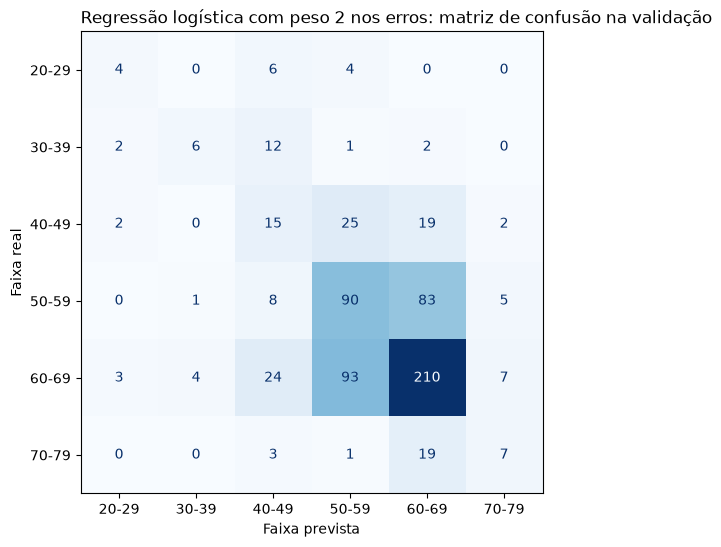

In [15]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_val, y_pred, labels=sorted(AGE_LABELS),
                                        display_labels=[AGE_LABELS[code] for code in sorted(AGE_LABELS)],
                                        cmap="Blues", ax=ax, colorbar=False)
ax.set(xlabel="Faixa prevista", ylabel="Faixa real")
ax.set_title(f"Regressão logística com peso {Config.MISCLASSIFIED_WEIGHT} nos erros: matriz de confusão na validação", loc="left")
plt.show()

## Um modelo de regressão logística por região do cérebro

A expressão gênica muda muito de uma região para outra, então aqui cada região tem o seu próprio modelo: ele é treinado só com as amostras de treino daquela região e avaliado só com as amostras de validação da mesma região. O modelo é o mesmo `Pipeline` da seção anterior (padronização e regressão logística), com o mesmo peso maior nas amostras erradas.

Métricas de cada região:

- F1 macro: média dos F1 das faixas etárias que aparecem na validação daquela região. Faixas sem nenhuma amostra na validação da região ficam de fora da média.
- Acurácia.
- Acerto com tolerância de 1 faixa: fração das amostras em que a faixa prevista é a correta ou uma vizinha.
- Erro médio em faixas: distância média entre a faixa prevista e a real.

Depois, as previsões de todas as regiões são reunidas para calcular as métricas gerais e a variação entre as regiões.

In [16]:
def region_metrics(y_true, y_pred):
    distance = np.abs(np.asarray(y_pred) - np.asarray(y_true))
    return {
        "F1 macro": f1_score(y_true, y_pred, labels=np.unique(y_true), average="macro", zero_division=0) * 100,
        "Acurácia": accuracy_score(y_true, y_pred) * 100,
        "Acerto com tolerância de 1 faixa": (distance <= 1).mean() * 100,
        "Erro médio em faixas": distance.mean(),
    }


region_models = {}
region_rows = {}
region_plain_pred = pd.Series(index=X_val.index, dtype=int)
region_pred = pd.Series(index=X_val.index, dtype=int)

for region in sorted(info_val["region"].unique()):
    train_mask = (info_train["region"] == region).to_numpy()
    val_mask = (info_val["region"] == region).to_numpy()
    X_region, y_region = X_train[train_mask], y_train[train_mask]

    plain, weighted, weights = compare_weighting(lr, X_region, y_region, groups_train[train_mask], X_val[val_mask])
    region_plain_pred[val_mask] = plain
    region_pred[val_mask] = weighted
    region_models[region] = fit_weighted(lr, X_region, y_region, weights)

    region_rows[region] = {
        "Amostras de treino": train_mask.sum(),
        "Amostras de validação": val_mask.sum(),
        "F1 macro sem peso": region_metrics(y_val[val_mask], plain)["F1 macro"],
        **region_metrics(y_val[val_mask], weighted),
    }

region_results = pd.DataFrame(region_rows).T.astype({"Amostras de treino": int, "Amostras de validação": int})
region_results.round(2).sort_values("F1 macro", ascending=False)

,Amostras de treino,Amostras de validação,F1 macro sem peso,F1 macro,Acurácia,Acerto com tolerância de 1 faixa,Erro médio em faixas
hypothalamus,139,52,27.16,41.56,53.85,90.38,0.58
spinal_cord_cervical_c-1,114,41,31.05,30.82,56.10,87.80,0.56
cerebellar_hemisphere,153,59,15.48,30.25,40.68,81.36,0.85
substantia_nigra,106,38,29.18,29.18,60.53,84.21,0.68
frontal_cortex_ba9,152,50,13.03,24.99,42.00,92.00,0.70
amygdala,101,40,13.82,23.33,30.00,82.50,0.90
hippocampus,145,50,19.49,23.26,48.00,84.00,0.68
anterior_cingulate_cortex_ba24,132,45,13.07,21.67,35.56,75.56,1.00
cerebellum,160,58,16.58,19.89,41.38,81.03,0.88
caudate_basal_ganglia,181,56,20.09,18.57,39.29,82.14,0.79


### Variação entre as regiões

Média, desvio padrão, variância, mínimo e máximo de cada métrica entre os 13 modelos.

In [17]:
metric_columns = ["F1 macro sem peso", "F1 macro", "Acurácia", "Acerto com tolerância de 1 faixa", "Erro médio em faixas"]
region_results[metric_columns].agg(["mean", "std", "var", "min", "max"]).rename(
    index={"mean": "Média", "std": "Desvio padrão", "var": "Variância", "min": "Mínimo", "max": "Máximo"}
).round(2)

,F1 macro sem peso,F1 macro,Acurácia,Acerto com tolerância de 1 faixa,Erro médio em faixas
Média,19.47,24.25,43.61,83.58,0.77
Desvio padrão,6.03,7.14,8.70,4.86,0.13
Variância,36.39,51.03,75.61,23.65,0.02
Mínimo,13.03,16.21,30.00,75.51,0.56
Máximo,31.05,41.56,60.53,92.00,1.00


### Todas as regiões juntas

As previsões dos 13 modelos são reunidas e comparadas com o modelo único da seção anterior, treinado com todas as regiões misturadas. Aqui o F1 macro considera as 6 faixas etárias.

In [18]:
pooled = pd.DataFrame({
    "Modelo único sem peso": evaluate(y_val, lr_plain),
    "Modelo único com peso": evaluate(y_val, y_pred),
    "Modelos por região sem peso": evaluate(y_val, region_plain_pred),
    "Modelos por região com peso": evaluate(y_val, region_pred),
})
pooled.loc["Acerto com tolerância de 1 faixa"] = [
    round(region_metrics(y_val, pred)["Acerto com tolerância de 1 faixa"], 2)
    for pred in [lr_plain, y_pred, region_plain_pred, region_pred]
]
pooled.loc["Erro médio em faixas"] = [
    round(region_metrics(y_val, pred)["Erro médio em faixas"], 2)
    for pred in [lr_plain, y_pred, region_plain_pred, region_pred]
]
pooled

,Modelo único sem peso,Modelo único com peso,Modelos por região sem peso,Modelos por região com peso
1 (20-29),0.00,32.00,0.00,10.00
2 (30-39),15.38,35.29,0.00,7.41
3 (40-49),16.33,22.90,16.13,19.12
4 (50-59),42.75,44.89,36.06,37.84
5 (60-69),64.57,62.31,56.47,56.41
6 (70-79),16.22,27.45,3.77,15.87
F1 macro,25.87,37.47,18.74,24.44
Acurácia,51.06,50.46,42.25,43.16
Acerto com tolerância de 1 faixa,90.27,88.30,84.19,83.59
Erro médio em faixas,0.61,0.64,0.78,0.78


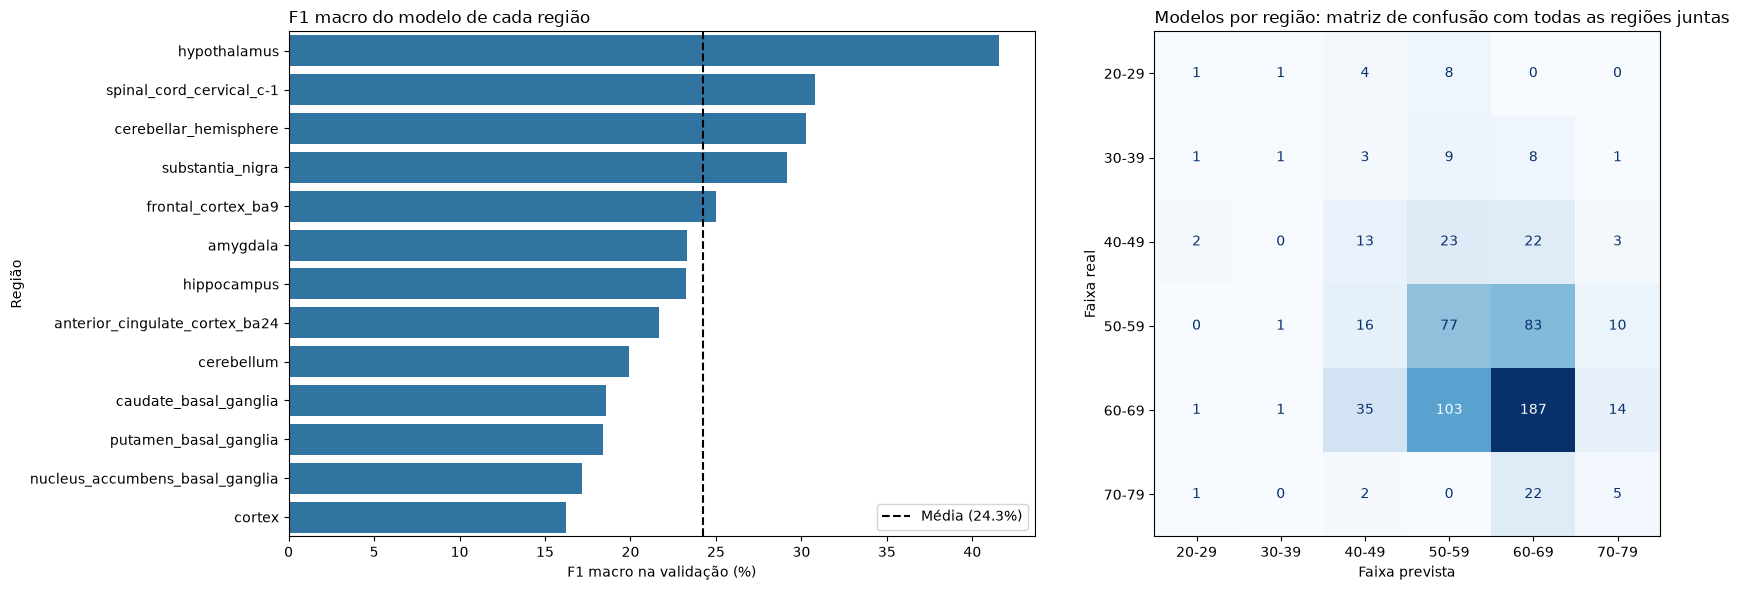

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

ordered = region_results.sort_values("F1 macro", ascending=False)
sns.barplot(x=ordered["F1 macro"], y=ordered.index, ax=axes[0])
axes[0].axvline(ordered["F1 macro"].mean(), color="black", linestyle="--", label=f"Média ({ordered['F1 macro'].mean():.1f}%)")
axes[0].set(xlabel="F1 macro na validação (%)", ylabel="Região")
axes[0].set_title("F1 macro do modelo de cada região", loc="left")
axes[0].legend()

ConfusionMatrixDisplay.from_predictions(y_val, region_pred, labels=sorted(AGE_LABELS),
                                        display_labels=[AGE_LABELS[code] for code in sorted(AGE_LABELS)],
                                        cmap="Blues", ax=axes[1], colorbar=False)
axes[1].set(xlabel="Faixa prevista", ylabel="Faixa real")
axes[1].set_title("Modelos por região: matriz de confusão com todas as regiões juntas", loc="left")

plt.tight_layout()
plt.show()

## Árvore de decisão e KNN

Os dois modelos seguem a aula das semanas 11 e 13: `DecisionTreeClassifier` e `KNeighborsClassifier(n_neighbors=3)`. Eles usam a mesma padronização da regressão logística, o mesmo peso maior nas amostras erradas e são avaliados na mesma validação, com as mesmas métricas.

In [20]:
models = {
    "Árvore de decisão": Pipeline([("scaler", StandardScaler()), ("clf", DecisionTreeClassifier(random_state=Config.RANDOM_STATE))]),
    "KNN (k = 3)": Pipeline([("scaler", StandardScaler()), ("clf", KNeighborsClassifier(n_neighbors=3))]),
}
plain_predictions = {"Regressão logística": lr_plain}
predictions = {"Regressão logística": y_pred}
for name, model in models.items():
    plain_predictions[name], predictions[name], _ = compare_weighting(model, X_train, y_train, groups_train, X_val)

display(pd.DataFrame({name: evaluate(y_val, pred) for name, pred in predictions.items()})
        .rename_axis(f"Com peso {Config.MISCLASSIFIED_WEIGHT} nos erros (validação, %)"))
pd.DataFrame({
    name: {
        "F1 macro sem peso": evaluate(y_val, plain_predictions[name])["F1 macro"],
        "F1 macro com peso": evaluate(y_val, predictions[name])["F1 macro"],
    }
    for name in predictions
})

,Regressão logística,Árvore de decisão,KNN (k = 3)
"Com peso 2 nos erros (validação, %)",,,
1 (20-29),32.00,0.00,0.00
2 (30-39),35.29,10.17,5.56
3 (40-49),22.90,9.52,20.22
4 (50-59),44.89,33.25,26.30
5 (60-69),62.31,50.16,46.49
6 (70-79),27.45,5.26,17.86
F1 macro,37.47,18.06,19.40
Acurácia,50.46,35.71,32.83


,Regressão logística,Árvore de decisão,KNN (k = 3)
F1 macro sem peso,25.87,19.96,19.42
F1 macro com peso,37.47,18.06,19.40


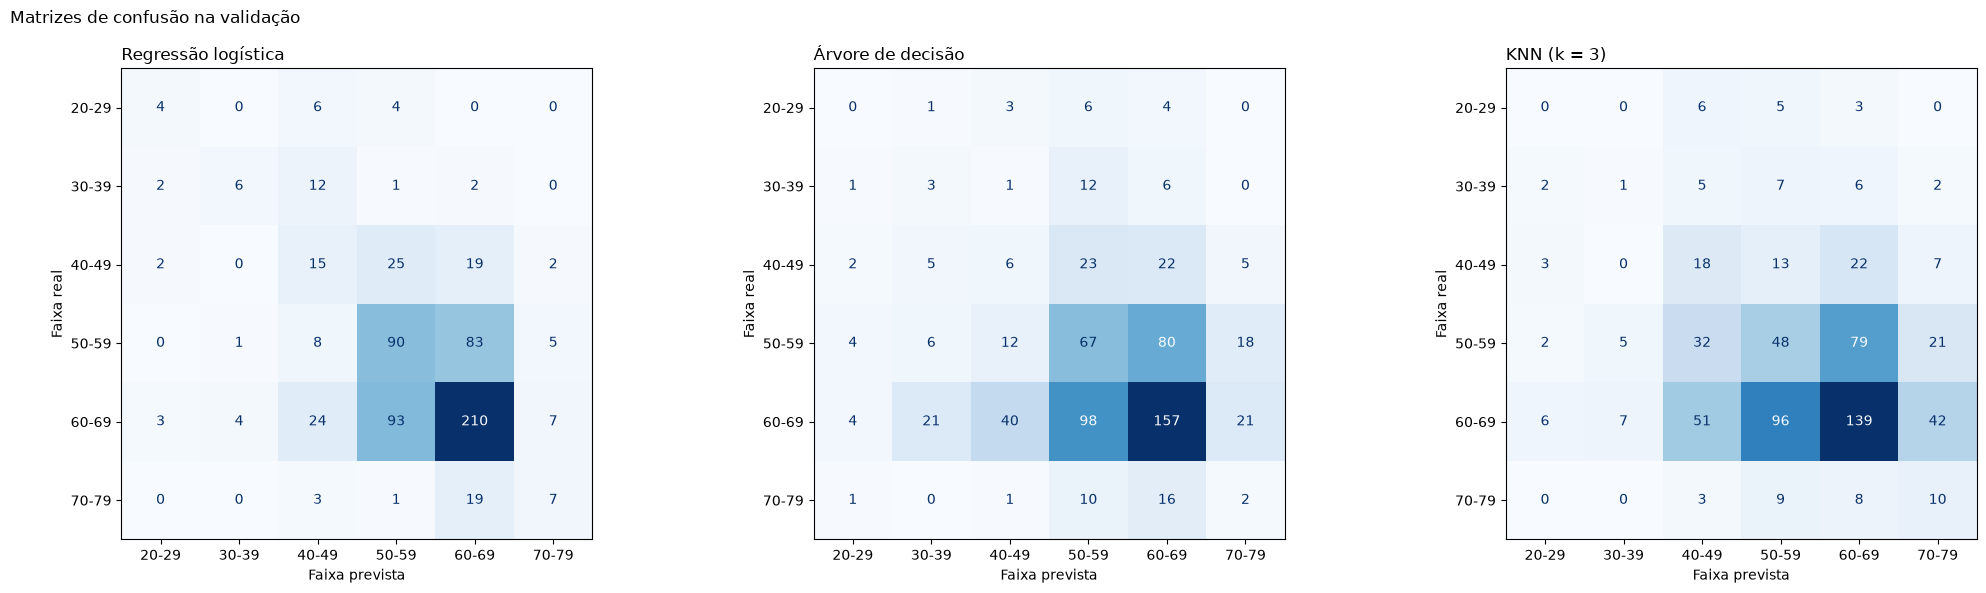

In [22]:
fig, axes = plt.subplots(1, len(predictions), figsize=(7 * len(predictions), 6))
for ax, (name, pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_val, pred, labels=sorted(AGE_LABELS),
                                            display_labels=[AGE_LABELS[code] for code in sorted(AGE_LABELS)],
                                            cmap="Blues", ax=ax, colorbar=False)
    ax.set(xlabel="Faixa prevista", ylabel="Faixa real")
    ax.set_title(name, loc="left")
fig.suptitle("Matrizes de confusão na validação", x=0.02, ha="left")
plt.tight_layout()
plt.show()

# Parte 2: faixas etárias agrupadas

Com as 6 faixas etárias, o F1 macro da regressão logística ficou baixo: a maioria dos erros acontece entre faixas vizinhas, e as faixas 20-29, 30-39 e 70-79 têm poucos doadores. Por isso, nesta segunda parte as faixas são agrupadas em 3 grupos de idade.

Os conjuntos de treino, validação e teste são os mesmos da parte 1. Só o alvo `y` é recalculado a partir da coluna `AGE`, com os grupos definidos em `GroupConfig.AGE_GROUPS`. As amostras sintéticas do treino recebem o grupo da faixa da amostra que as gerou. As funções de peso nas amostras erradas são as mesmas da parte 1.

In [24]:
class GroupConfig:
    AGE_GROUPS = {
        "20-49": ["20-29", "30-39", "40-49"],
        "50-59": ["50-59"],
        "60-79": ["60-69", "70-79"],
    }
    MAX_ITER = 2000
    REGION_MAX_ITER = 300
    MISCLASSIFIED_WEIGHT = 3
    SIGNIFICANCE_LEVEL = 0.05

In [25]:
GROUP_LABELS = {code: group for code, group in enumerate(GroupConfig.AGE_GROUPS, start=1)}
AGE_TO_GROUP = {age: code for code, ages in enumerate(GroupConfig.AGE_GROUPS.values(), start=1) for age in ages}

y_train_groups = info_train["AGE"].map(AGE_TO_GROUP).astype(int)
y_val_groups = info_val["AGE"].map(AGE_TO_GROUP).astype(int)
y_test_groups = info_test["AGE"].map(AGE_TO_GROUP).astype(int)

group_counts = pd.DataFrame({
    "train": y_train_groups.value_counts().sort_index(),
    "val": y_val_groups.value_counts().sort_index(),
    "test": y_test_groups.value_counts().sort_index(),
})
group_counts.index = [f"{code} ({GROUP_LABELS[code]})" for code in group_counts.index]
group_donors = pd.DataFrame({
    name: info["SUBJID"].groupby(info["AGE"].map(AGE_TO_GROUP)).nunique()
    for name, info in {"train": info_train, "val": info_val, "test": info_test}.items()
})
group_donors.index = group_counts.index
pd.concat({"Amostras": group_counts, "Doadores": group_donors}, axis=1)

Amostras           Doadores         
             train  val test    train val test
1 (20-49)      554  100   35       38  11    5
2 (50-59)      455  187  101       80  24   12
3 (60-79)      844  371  179      151  44   23

## Métricas dos grupos de idade

F1 de cada grupo, F1 macro, acurácia, acerto com tolerância de 1 grupo (o grupo previsto é o correto ou um vizinho) e erro médio em grupos (distância média entre o grupo previsto e o real).

In [26]:
def evaluate_groups(y_true, y_pred):
    classes = sorted(GROUP_LABELS)
    distance = np.abs(np.asarray(y_pred) - np.asarray(y_true))
    per_class = pd.Series(f1_score(y_true, y_pred, labels=classes, average=None, zero_division=0) * 100,
                          index=[f"{code} ({GROUP_LABELS[code]})" for code in classes])
    summary = pd.Series({
        "F1 macro": f1_score(y_true, y_pred, labels=classes, average="macro", zero_division=0) * 100,
        "Acurácia": accuracy_score(y_true, y_pred) * 100,
        "Acerto com tolerância de 1 grupo": (distance <= 1).mean() * 100,
        "Erro médio em grupos": distance.mean(),
    })
    return pd.concat([per_class, summary]).round(2)


def plot_confusion_groups(y_true, y_pred, title, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=sorted(GROUP_LABELS),
                                            display_labels=[GROUP_LABELS[code] for code in sorted(GROUP_LABELS)],
                                            cmap="Blues", ax=ax, colorbar=False)
    ax.set(xlabel="Grupo previsto", ylabel="Grupo real")
    ax.set_title(title, loc="left")

## Regressão logística com todas as regiões (grupos de idade)

Um único modelo treinado com as amostras de todas as regiões, sem peso e com peso `GroupConfig.MISCLASSIFIED_WEIGHT` nas amostras erradas.

In [27]:
lr_groups = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=GroupConfig.MAX_ITER, random_state=Config.RANDOM_STATE)),
])
lr_groups_plain, lr_groups_pred, lr_groups_weights = compare_weighting(
    lr_groups, X_train, y_train_groups, groups_train, X_val, weight=GroupConfig.MISCLASSIFIED_WEIGHT
)
print(f"Amostras de treino erradas na validação cruzada: {(lr_groups_weights > 1).sum()} de {len(lr_groups_weights)}")

pd.DataFrame({
    "Sem peso": evaluate_groups(y_val_groups, lr_groups_plain),
    f"Com peso {GroupConfig.MISCLASSIFIED_WEIGHT} nos erros": evaluate_groups(y_val_groups, lr_groups_pred),
}).rename_axis("Regressão logística, grupos de idade (validação)")

Amostras de treino erradas na validação cruzada: 683 de 1853


,Sem peso,Com peso 3 nos erros
"Regressão logística, grupos de idade (validação)",,
1 (20-49),56.85,61.46
2 (50-59),40.34,44.44
3 (60-79),71.45,71.37
F1 macro,56.21,59.09
Acurácia,60.94,62.01
Acerto com tolerância de 1 grupo,92.86,94.68
Erro médio em grupos,0.46,0.43


In [47]:
# Keep the best model (weight on the misclassified samples) and save it for correlation.ipynb
import importlib

import joblib

import src.config

importlib.reload(src.config)
from src.config import BEST_MODEL_FILE

lr_groups_model = fit_weighted(lr_groups, X_train, y_train_groups, lr_groups_weights)
assert (lr_groups_model.predict(X_val) == lr_groups_pred).all()
BEST_MODEL_FILE.parent.mkdir(parents=True, exist_ok=True)
joblib.dump({"model": lr_groups_model, "age_groups": GroupConfig.AGE_GROUPS,
             "misclassified_weight": GroupConfig.MISCLASSIFIED_WEIGHT}, BEST_MODEL_FILE)
print(f"Melhor modelo salvo em {BEST_MODEL_FILE.relative_to(BEST_MODEL_FILE.parents[2])}")

Melhor modelo salvo em datasets/processed/best_model_age_groups.joblib


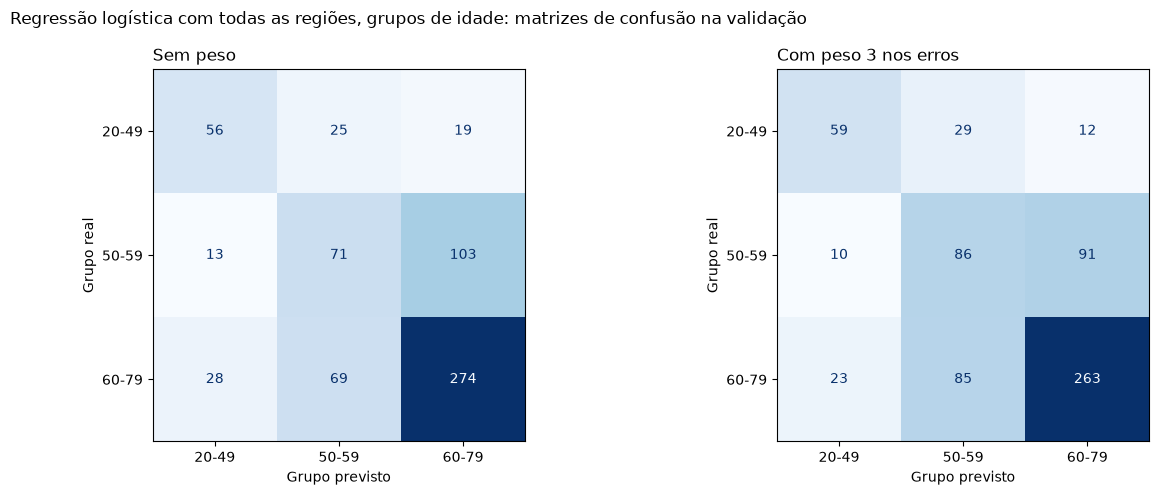

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_confusion_groups(y_val_groups, lr_groups_plain, "Sem peso", axes[0])
plot_confusion_groups(y_val_groups, lr_groups_pred, f"Com peso {GroupConfig.MISCLASSIFIED_WEIGHT} nos erros", axes[1])
fig.suptitle("Regressão logística com todas as regiões, grupos de idade: matrizes de confusão na validação", x=0.02, ha="left")
plt.tight_layout()
plt.show()

## Um modelo por região do cérebro (grupos de idade)

Cada região tem o seu próprio modelo, treinado só com as amostras de treino daquela região e avaliado só com as amostras de validação da mesma região, com o mesmo peso nas amostras erradas. Para essa etapa ser mais rápida, cada modelo usa no máximo `GroupConfig.REGION_MAX_ITER` iterações; se não convergir, o scikit-learn mostra um `ConvergenceWarning`.

In [29]:
lr_groups_region = clone(lr_groups).set_params(clf__max_iter=GroupConfig.REGION_MAX_ITER)

group_region_rows = {}
group_region_plain_pred = pd.Series(0, index=X_val.index)
group_region_pred = pd.Series(0, index=X_val.index)

for region in sorted(info_val["region"].dropna().unique()):
    train_mask = (info_train["region"] == region).to_numpy()
    val_mask = (info_val["region"] == region).to_numpy()

    plain, weighted, _ = compare_weighting(
        lr_groups_region, X_train[train_mask], y_train_groups[train_mask], groups_train[train_mask], X_val[val_mask],
        weight=GroupConfig.MISCLASSIFIED_WEIGHT,
    )
    group_region_plain_pred[val_mask] = plain
    group_region_pred[val_mask] = weighted

    scores = evaluate_groups(y_val_groups[val_mask], weighted)
    group_region_rows[region] = {
        "Amostras de treino": train_mask.sum(),
        "Amostras de validação": val_mask.sum(),
        "F1 macro sem peso": evaluate_groups(y_val_groups[val_mask], plain)["F1 macro"],
        **scores[["F1 macro", "Acurácia", "Acerto com tolerância de 1 grupo", "Erro médio em grupos"]].to_dict(),
    }

group_region_results = pd.DataFrame(group_region_rows).T.astype({"Amostras de treino": int, "Amostras de validação": int})
group_region_results.round(2).sort_values("F1 macro", ascending=False)

,Amostras de treino,Amostras de validação,F1 macro sem peso,F1 macro,Acurácia,Acerto com tolerância de 1 grupo,Erro médio em grupos
substantia_nigra,106,38,61.21,61.21,68.42,89.47,0.42
putamen_basal_ganglia,143,49,49.41,52.01,57.14,81.63,0.61
anterior_cingulate_cortex_ba24,132,45,49.94,51.02,53.33,82.22,0.64
spinal_cord_cervical_c-1,114,41,44.84,50.96,63.41,90.24,0.46
hypothalamus,139,52,48.54,50.19,55.77,94.23,0.50
cerebellar_hemisphere,153,59,47.70,47.70,47.46,88.14,0.64
cortex,160,60,41.44,47.22,53.33,86.67,0.60
cerebellum,160,58,42.20,45.36,44.83,93.10,0.62
hippocampus,145,50,43.12,44.04,56.00,92.00,0.52
caudate_basal_ganglia,181,56,45.51,43.49,50.00,85.71,0.64


### Variação entre as regiões (grupos de idade)

In [30]:
group_metric_columns = ["F1 macro sem peso", "F1 macro", "Acurácia", "Acerto com tolerância de 1 grupo", "Erro médio em grupos"]
group_region_results[group_metric_columns].agg(["mean", "std", "var", "min", "max"]).rename(
    index={"mean": "Média", "std": "Desvio padrão", "var": "Variância", "min": "Mínimo", "max": "Máximo"}
).round(2)

,F1 macro sem peso,F1 macro,Acurácia,Acerto com tolerância de 1 grupo,Erro médio em grupos
Média,44.38,46.25,52.22,88.52,0.59
Desvio padrão,7.87,7.91,8.89,6.31,0.12
Variância,61.86,62.65,79.00,39.77,0.01
Mínimo,28.44,28.44,32.50,75.00,0.42
Máximo,61.21,61.21,68.42,98.33,0.92


### Todas as regiões juntas (grupos de idade)

In [31]:
pd.DataFrame({
    "Modelo único sem peso": evaluate_groups(y_val_groups, lr_groups_plain),
    "Modelo único com peso": evaluate_groups(y_val_groups, lr_groups_pred),
    "Modelos por região sem peso": evaluate_groups(y_val_groups, group_region_plain_pred),
    "Modelos por região com peso": evaluate_groups(y_val_groups, group_region_pred),
})

,Modelo único sem peso,Modelo único com peso,Modelos por região sem peso,Modelos por região com peso
1 (20-49),56.85,61.46,37.14,39.27
2 (50-59),40.34,44.44,33.15,36.46
3 (60-79),71.45,71.37,64.23,63.96
F1 macro,56.21,59.09,44.84,46.56
Acurácia,60.94,62.01,51.22,51.82
Acerto com tolerância de 1 grupo,92.86,94.68,88.60,88.91
Erro médio em grupos,0.46,0.43,0.60,0.59


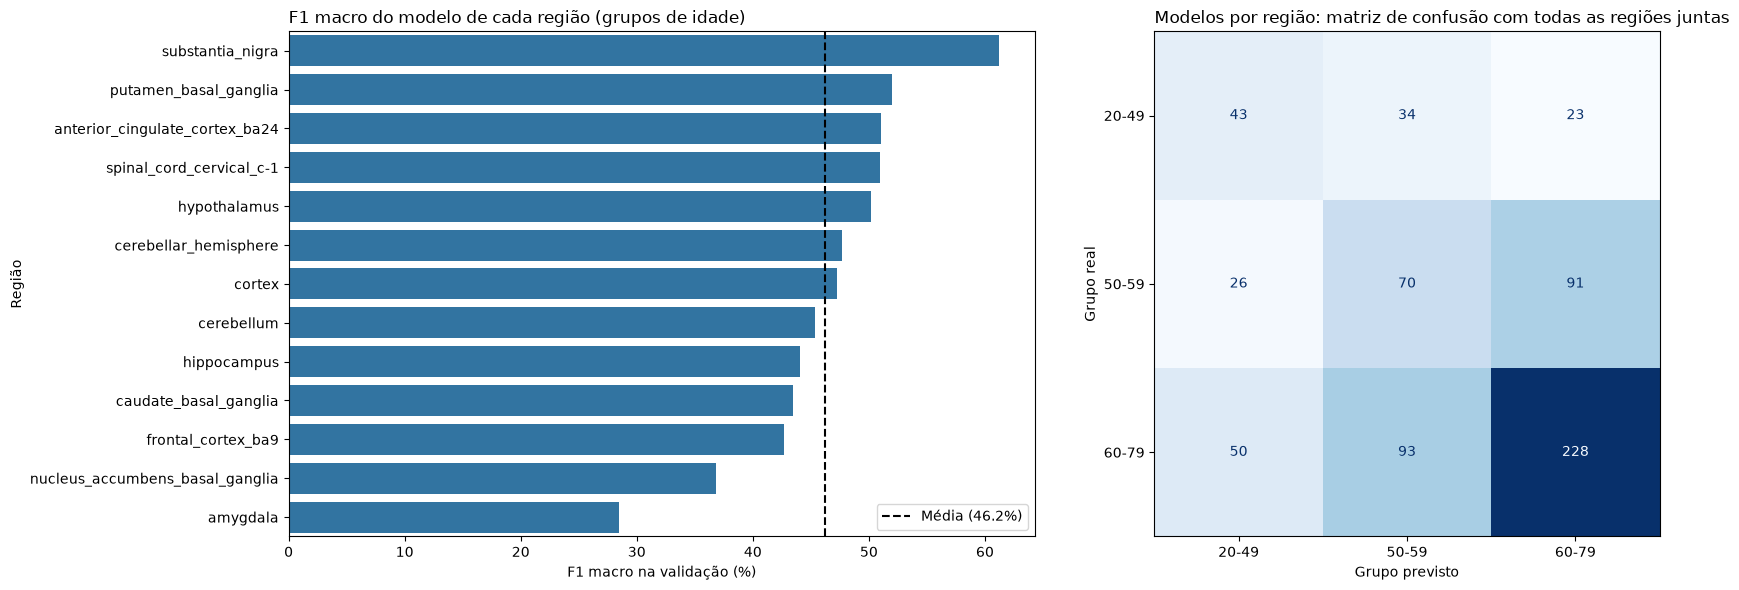

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

ordered = group_region_results.sort_values("F1 macro", ascending=False)
sns.barplot(x=ordered["F1 macro"], y=ordered.index, ax=axes[0])
axes[0].axvline(ordered["F1 macro"].mean(), color="black", linestyle="--", label=f"Média ({ordered['F1 macro'].mean():.1f}%)")
axes[0].set(xlabel="F1 macro na validação (%)", ylabel="Região")
axes[0].set_title("F1 macro do modelo de cada região (grupos de idade)", loc="left")
axes[0].legend()

plot_confusion_groups(y_val_groups, group_region_pred, "Modelos por região: matriz de confusão com todas as regiões juntas", axes[1])

plt.tight_layout()
plt.show()

## Testes de significância estatística (grupos de idade)

O teste de Friedman compara os 4 modelos ao mesmo tempo, e o teste de Wilcoxon (pareado, não paramétrico) compara os modelos dois a dois. Os dois testes precisam de vários resultados de cada modelo, medidos nos mesmos blocos. Aqui os blocos são as 13 regiões do cérebro: para cada região, calculamos o F1 macro de cada modelo nas amostras de validação daquela região. Assim, cada modelo tem 13 valores de F1, pareados por região.

Modelos comparados:

- Modelo único sem peso.
- Modelo único com peso `MISCLASSIFIED_WEIGHT` nas amostras erradas.
- Modelos por região sem peso.
- Modelos por região com peso.

Hipótese nula: os modelos têm o mesmo desempenho. Ela é rejeitada quando p < `SIGNIFICANCE_LEVEL`.

1. Único sem peso × Único com peso 3
2. Único sem peso × Por região sem peso
3. Único sem peso × Por região com peso 3
4. Único com peso 3 × Por região sem peso
5. Único com peso 3 × Por região com peso 3
6. Por região sem peso × Por região com peso 3

A tabela também mostra o p-value com a correção de Bonferroni (p multiplicado pelo número de comparações), que reduz a chance de encontrar uma diferença por acaso.

Limitação: as 13 regiões não são blocos totalmente independentes, porque um mesmo doador pode ter amostras em várias regiões.

In [33]:
from itertools import combinations

from scipy.stats import friedmanchisquare, wilcoxon

group_variants = {
    "Modelo único sem peso": np.asarray(lr_groups_plain),
    f"Modelo único com peso {GroupConfig.MISCLASSIFIED_WEIGHT}": np.asarray(lr_groups_pred),
    "Por região sem peso": group_region_plain_pred.to_numpy(),
    f"Por região com peso {GroupConfig.MISCLASSIFIED_WEIGHT}": group_region_pred.to_numpy(),
}

f1_by_region = pd.DataFrame({
    name: {
        region: evaluate_groups(y_val_groups[(info_val["region"] == region).to_numpy()],
                                pred[(info_val["region"] == region).to_numpy()])["F1 macro"]
        for region in sorted(info_val["region"].dropna().unique())
    }
    for name, pred in group_variants.items()
})

display(f1_by_region.round(2))
pd.DataFrame({
    "F1 macro médio": f1_by_region.mean(),
    "Desvio padrão": f1_by_region.std(),
    "Posto médio (1 = melhor)": f1_by_region.rank(axis=1, ascending=False).mean(),
}).round(2).sort_values("Posto médio (1 = melhor)")

,Modelo único sem peso,Modelo único com peso 3,Por região sem peso,Por região com peso 3
amygdala,62.48,55.25,28.44,28.44
anterior_cingulate_cortex_ba24,63.94,67.29,49.94,51.02
caudate_basal_ganglia,46.20,54.14,45.51,43.49
cerebellar_hemisphere,51.89,59.74,47.70,47.70
cerebellum,49.47,52.29,42.20,45.36
cortex,55.83,60.54,41.44,47.22
frontal_cortex_ba9,44.76,49.05,38.64,42.70
hippocampus,54.43,59.32,43.12,44.04
hypothalamus,63.08,65.26,48.54,50.19
nucleus_accumbens_basal_ganglia,61.52,61.15,35.95,36.86


,F1 macro médio,Desvio padrão,Posto médio (1 = melhor)
Modelo único com peso 3,59.24,6.48,1.38
Modelo único sem peso,57.25,9.26,1.85
Por região com peso 3,46.25,7.91,3.04
Por região sem peso,44.38,7.87,3.73


In [34]:
friedman_stat, friedman_p = friedmanchisquare(*[f1_by_region[name] for name in f1_by_region.columns])
print(f"Friedman: estatística = {friedman_stat:.3f}, p = {friedman_p:.4f}")
if friedman_p < GroupConfig.SIGNIFICANCE_LEVEL:
    print(f"Há diferença estatisticamente significativa entre os modelos (p < {GroupConfig.SIGNIFICANCE_LEVEL}).")
else:
    print(f"Não há diferença estatisticamente significativa entre os modelos (p >= {GroupConfig.SIGNIFICANCE_LEVEL}).")

Friedman: estatística = 27.756, p = 0.0000
Há diferença estatisticamente significativa entre os modelos (p < 0.05).


In [35]:
pairs = list(combinations(f1_by_region.columns, 2))
rows = []
for first, second in pairs:
    difference = f1_by_region[first] - f1_by_region[second]
    p_value = 1.0 if np.allclose(difference, 0) else wilcoxon(f1_by_region[first], f1_by_region[second]).pvalue
    corrected = min(p_value * len(pairs), 1.0)
    rows.append({
        "Modelo A": first,
        "Modelo B": second,
        "Diferença média de F1 (A - B)": difference.mean(),
        "p (Wilcoxon)": p_value,
        "p corrigido (Bonferroni)": corrected,
        "Significativo após correção": corrected < GroupConfig.SIGNIFICANCE_LEVEL,
    })

pd.DataFrame(rows).round(4)

,Modelo A,Modelo B,Diferença média de F1 (A - B),p (Wilcoxon),p corrigido (Bonferroni),Significativo após correção
0,Modelo único sem peso,Modelo único com peso 3,-1.9908,0.1465,0.8789,False
1,Modelo único sem peso,Por região sem peso,12.8692,0.0007,0.0044,True
2,Modelo único sem peso,Por região com peso 3,11.0031,0.0012,0.0073,True
3,Modelo único com peso 3,Por região sem peso,14.8600,0.0002,0.0015,True
4,Modelo único com peso 3,Por região com peso 3,12.9938,0.0005,0.0029,True
5,Por região sem peso,Por região com peso 3,-1.8662,0.0195,0.1172,False


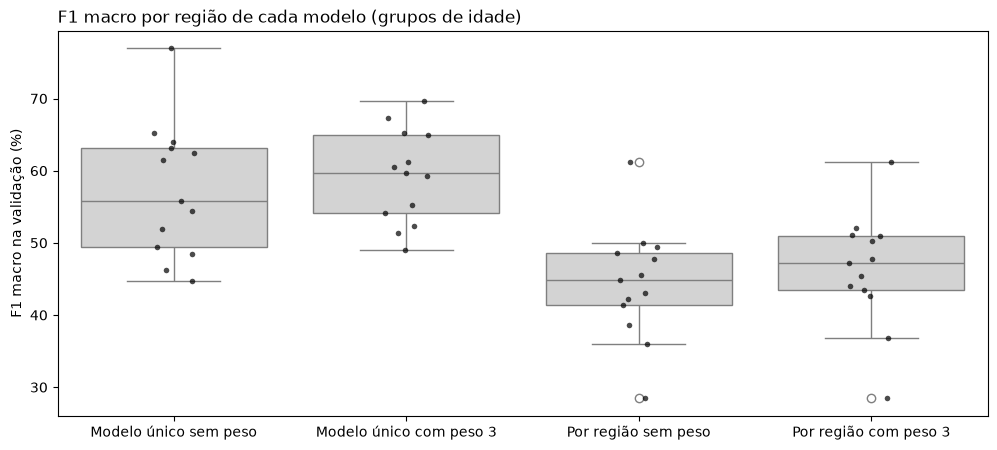

In [36]:
f1_long = f1_by_region.melt(var_name="Modelo", value_name="F1 macro")

plt.figure(figsize=(12, 5))
sns.boxplot(data=f1_long, x="Modelo", y="F1 macro", color="lightgray")
sns.stripplot(data=f1_long, x="Modelo", y="F1 macro", color="black", size=4, alpha=0.7)
plt.xlabel("")
plt.ylabel("F1 macro na validação (%)")
plt.title("F1 macro por região de cada modelo (grupos de idade)", loc="left")
plt.show()

## Box-Cox no melhor modelo (modelo único com peso 3)

Mesmo depois do log2(TPM + 1), muitos genes continuam com distribuição assimétrica no treino. Aqui testamos o `PowerTransformer(method="box-cox")` (aula da semana 10) para deixar a distribuição de cada gene mais próxima da normal antes de treinar o melhor modelo da parte 2: a regressão logística única com peso `GroupConfig.MISCLASSIFIED_WEIGHT` nas amostras erradas.

O Box-Cox só funciona com valores estritamente positivos, e log2(TPM + 1) pode ser zero. Por isso, antes do Box-Cox, somamos 1 a todos os valores. O Box-Cox fica dentro do `Pipeline`, então o parâmetro de cada gene é estimado só nos dados de treino de cada rodada (incluindo a validação cruzada que encontra as amostras erradas) e depois aplicado à validação. Com `standardize=True`, o próprio Box-Cox já padroniza os genes (média 0 e desvio padrão 1), substituindo o `StandardScaler`.

In [37]:
# Fit Box-Cox on the training set only and compare the skewness of the genes before and after
from sklearn.preprocessing import FunctionTransformer, PowerTransformer


def shift_positive(X):
    return X + 1


boxcox = Pipeline([
    ("shift", FunctionTransformer(shift_positive)),
    ("boxcox", PowerTransformer(method="box-cox", standardize=True)),
])
X_train_boxcox = pd.DataFrame(boxcox.fit_transform(X_train), index=X_train.index, columns=X_train.columns)

skew_comparison = pd.DataFrame({
    "Antes do Box-Cox": X_train.skew(),
    "Depois do Box-Cox": X_train_boxcox.skew(),
})
display(skew_comparison.describe().round(2).rename_axis("Assimetria dos genes no treino"))
print("Genes com |assimetria| > 1:", (skew_comparison.abs() > 1).sum().to_dict())

,Antes do Box-Cox,Depois do Box-Cox
Assimetria dos genes no treino,,
count,17500.00,17500.00
mean,0.25,-0.00
std,0.67,0.09
min,-5.70,-0.49
25%,-0.25,-0.03
50%,0.20,-0.00
75%,0.67,0.01
max,6.16,1.97


Genes com |assimetria| > 1: {'Antes do Box-Cox': 2362, 'Depois do Box-Cox': 22}


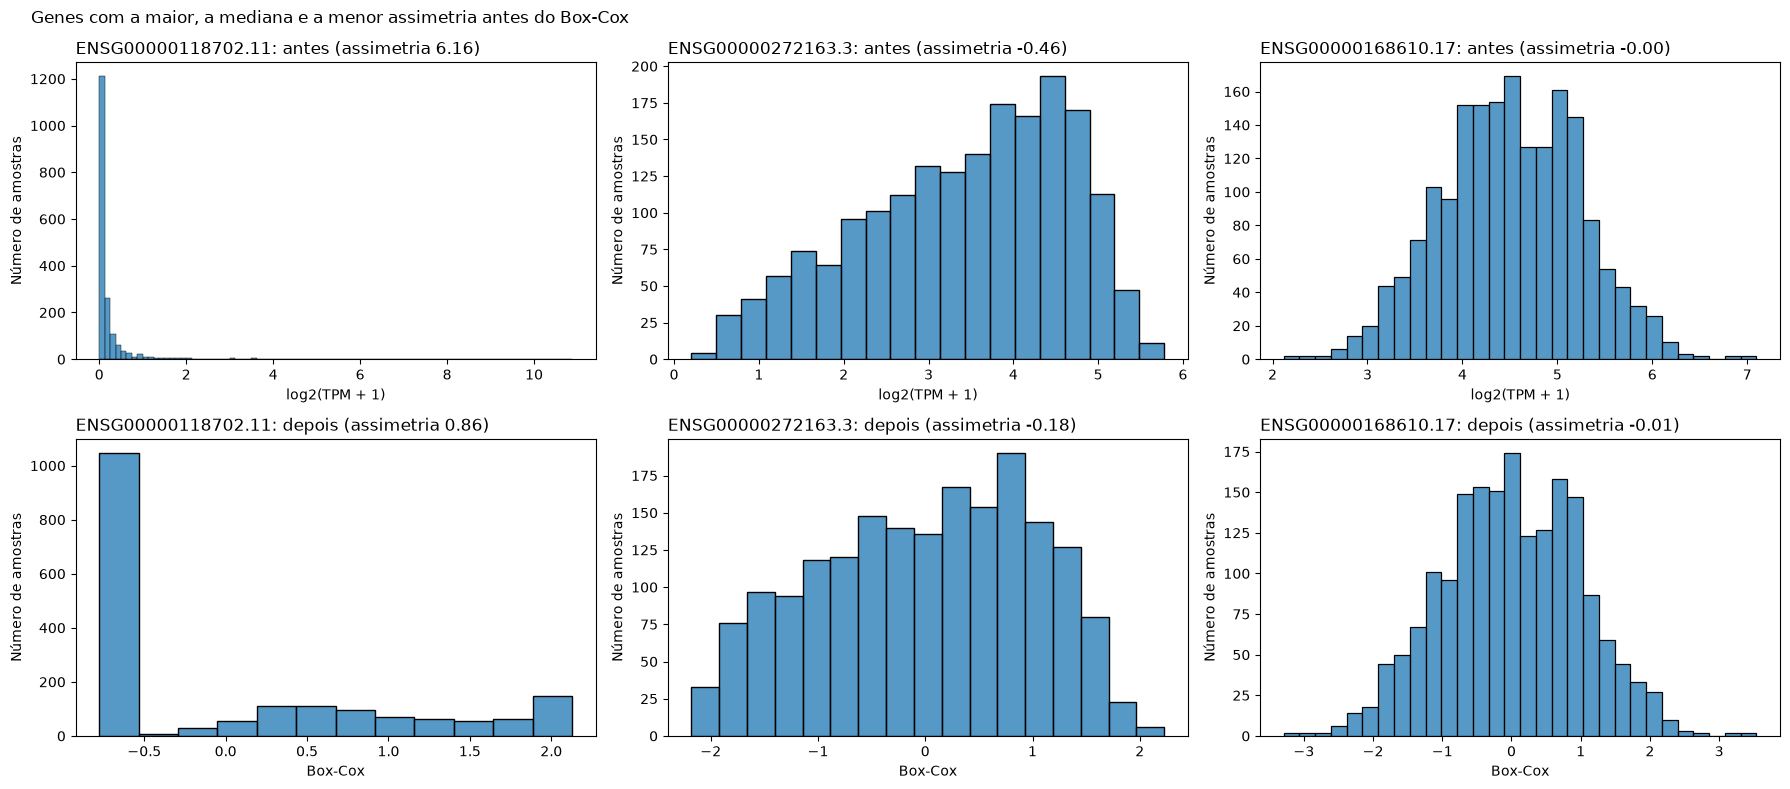

In [38]:
# Distribution of three example genes before and after Box-Cox
example_genes = skew_comparison["Antes do Box-Cox"].abs().sort_values(ascending=False).index[[0, len(skew_comparison) // 2, -1]]

fig, axes = plt.subplots(2, len(example_genes), figsize=(18, 8))
for col, gene in enumerate(example_genes):
    sns.histplot(X_train[gene], ax=axes[0, col])
    axes[0, col].set(xlabel="log2(TPM + 1)", ylabel="Número de amostras")
    axes[0, col].set_title(f"{gene}: antes (assimetria {skew_comparison.loc[gene, 'Antes do Box-Cox']:.2f})", loc="left")
    sns.histplot(X_train_boxcox[gene], ax=axes[1, col])
    axes[1, col].set(xlabel="Box-Cox", ylabel="Número de amostras")
    axes[1, col].set_title(f"{gene}: depois (assimetria {skew_comparison.loc[gene, 'Depois do Box-Cox']:.2f})", loc="left")
fig.suptitle("Genes com a maior, a mediana e a menor assimetria antes do Box-Cox", x=0.02, ha="left")
plt.tight_layout()
plt.show()

del X_train_boxcox

In [39]:
# Train the single model with weight 3 on the misclassified samples, using Box-Cox instead of StandardScaler
lr_groups_boxcox = Pipeline([
    ("shift", FunctionTransformer(shift_positive)),
    ("boxcox", PowerTransformer(method="box-cox", standardize=True)),
    ("clf", LogisticRegression(max_iter=GroupConfig.MAX_ITER, random_state=Config.RANDOM_STATE)),
])
boxcox_weights = misclassified_weights(lr_groups_boxcox, X_train, y_train_groups, groups_train, GroupConfig.MISCLASSIFIED_WEIGHT)
lr_groups_boxcox_model = fit_weighted(lr_groups_boxcox, X_train, y_train_groups, boxcox_weights)
lr_groups_boxcox_pred = lr_groups_boxcox_model.predict(X_val)
print(f"Amostras de treino erradas na validação cruzada: {(boxcox_weights > 1).sum()} de {len(boxcox_weights)}")

pd.DataFrame({
    f"Com peso {GroupConfig.MISCLASSIFIED_WEIGHT} (StandardScaler)": evaluate_groups(y_val_groups, lr_groups_pred),
    f"Com peso {GroupConfig.MISCLASSIFIED_WEIGHT} (Box-Cox)": evaluate_groups(y_val_groups, lr_groups_boxcox_pred),
}).rename_axis("Modelo único, grupos de idade (validação)")

Amostras de treino erradas na validação cruzada: 659 de 1853


,Com peso 3 (StandardScaler),Com peso 3 (Box-Cox)
"Modelo único, grupos de idade (validação)",,
1 (20-49),61.46,57.00
2 (50-59),44.44,42.44
3 (60-79),71.37,70.09
F1 macro,59.09,56.51
Acurácia,62.01,60.18
Acerto com tolerância de 1 grupo,94.68,93.16
Erro médio em grupos,0.43,0.47


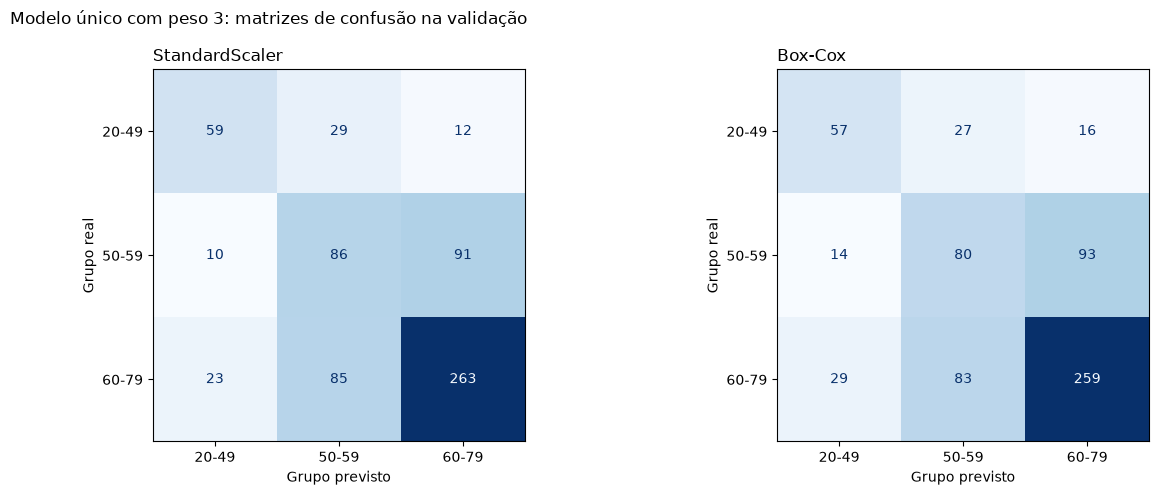

In [40]:
# Confusion matrices of the single model with weight 3, without and with Box-Cox
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_confusion_groups(y_val_groups, lr_groups_pred, "StandardScaler", axes[0])
plot_confusion_groups(y_val_groups, lr_groups_boxcox_pred, "Box-Cox", axes[1])
fig.suptitle(f"Modelo único com peso {GroupConfig.MISCLASSIFIED_WEIGHT}: matrizes de confusão na validação", x=0.02, ha="left")
plt.tight_layout()
plt.show()

In [41]:
# Wilcoxon test on the per-region F1 macro: single model with weight 3, without and with Box-Cox
region_masks = {region: (info_val["region"] == region).to_numpy() for region in sorted(info_val["region"].dropna().unique())}
f1_boxcox = pd.DataFrame({
    "StandardScaler": {region: evaluate_groups(y_val_groups[mask], lr_groups_pred[mask])["F1 macro"] for region, mask in region_masks.items()},
    "Box-Cox": {region: evaluate_groups(y_val_groups[mask], lr_groups_boxcox_pred[mask])["F1 macro"] for region, mask in region_masks.items()},
})
display(f1_boxcox.round(2))

difference = f1_boxcox["Box-Cox"] - f1_boxcox["StandardScaler"]
p_value = 1.0 if np.allclose(difference, 0) else wilcoxon(f1_boxcox["Box-Cox"], f1_boxcox["StandardScaler"]).pvalue
print(f"Diferença média de F1 macro (Box-Cox - StandardScaler): {difference.mean():.2f} pontos")
print(f"Wilcoxon: p = {p_value:.4f}")
if p_value < GroupConfig.SIGNIFICANCE_LEVEL:
    print(f"Há diferença estatisticamente significativa (p < {GroupConfig.SIGNIFICANCE_LEVEL}).")
else:
    print(f"Não há diferença estatisticamente significativa (p >= {GroupConfig.SIGNIFICANCE_LEVEL}).")

,StandardScaler,Box-Cox
amygdala,55.25,55.07
anterior_cingulate_cortex_ba24,67.29,69.52
caudate_basal_ganglia,54.14,53.76
cerebellar_hemisphere,59.74,57.12
cerebellum,52.29,55.88
cortex,60.54,58.83
frontal_cortex_ba9,49.05,44.46
hippocampus,59.32,55.61
hypothalamus,65.26,58.22
nucleus_accumbens_basal_ganglia,61.15,57.31


Diferença média de F1 macro (Box-Cox - StandardScaler): -3.03 pontos
Wilcoxon: p = 0.0327
Há diferença estatisticamente significativa (p < 0.05).
